In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

import os

In [3]:
class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            padding=1,
            stride=stride,
            bias=False,
        )
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)

        self.conv2 = nn.Conv2d(
            out_channels, out_channels, kernel_size=3, padding=1, stride=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels, out_channels, kernel_size=1, stride=stride, bias=False
                ),
                nn.BatchNorm2d(out_channels),
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        shortcut = self.shortcut(x)

        out = out + shortcut
        out = self.relu(out)

        return out


class ResNet18(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.conv = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)

        self.layer1 = self.make_layer(64, 64, 2, 1)
        self.layer2 = self.make_layer(64, 128, 2, 2)
        self.layer3 = self.make_layer(128, 256, 2, 2)
        self.layer4 = self.make_layer(256, 512, 2, 2)

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.flatten = nn.Flatten()

        self.fc = nn.Linear(512, num_classes)

    def make_layer(self, in_channels, out_channels, n_layers, stride):
        layers = []
        layers.append(BasicBlock(in_channels, out_channels, stride=stride))

        for _ in range(1, n_layers):
            layers.append(BasicBlock(out_channels, out_channels, stride=1))

        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.conv(x)
        x = self.bn(x)
        x = self.relu(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        x = self.pool(x)
        x = self.flatten(x)
        x = self.fc(x)

        return x

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Mean and Std of RGB
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

BATCH_SIZE = 128

train_transform = transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_dataset = torchvision.datasets.CIFAR10(
    root="/content/drive/MyDrive/datasets",
    train=True,
    download=False,
    transform=train_transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="/content/drive/MyDrive/datasets",
    train=False,
    download=False,
    transform=test_transform
)

train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda"),
    persistent_workers=True,
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda"),
    persistent_workers=True,
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

Training samples: 50000
Testing samples: 10000


In [5]:
model = ResNet18().to(device)
print(model)

ResNet18(
  (conv): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (shortcut): Identity()
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 

In [6]:
LR = 0.001
EPOCHS = 20

optimizer = optim.Adam(model.parameters(), lr=LR, weight_decay=5e-4)
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=LR, steps_per_epoch=len(train_loader), epochs=EPOCHS
)
loss_fn = nn.CrossEntropyLoss()

def train_one_epoch():
    epoch_total_loss = 0.0
    epoch_total = 0
    epoch_correct = 0

    model.train()

    for images, labels in train_loader:
        n = images.size(0)

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        logits = model(images)
        loss = loss_fn(logits, labels)

        loss.backward()
        optimizer.step()
        scheduler.step()

        predictions = logits.argmax(dim=1)

        epoch_total_loss += loss.item() * n
        epoch_total += n
        epoch_correct += (predictions == labels).sum().item()

    epoch_loss = epoch_total_loss / epoch_total
    epoch_accuracy = 100 * epoch_correct / epoch_total

    return epoch_loss, epoch_accuracy


@torch.no_grad()
def evaluate():
    model.eval()

    correct = 0.0
    total = 0.0
    total_loss = 0.0

    for images, labels in test_loader:
        n = images.size(0)

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        logits = model(images)
        loss = loss_fn(logits, labels)

        predictions = logits.argmax(dim=1)

        total_loss += loss.item() * n
        total += n
        correct += (predictions == labels).sum().item()

    test_loss = total_loss / total
    test_accuracy = 100 * correct / total

    return test_loss, test_accuracy


# Checkpointing
CHECKPOINT_DIR = "/content/drive/MyDrive/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

CHECKPOINT_PATH = os.path.join(CHECKPOINT_DIR, "latest.pth")
BEST_PATH = os.path.join(CHECKPOINT_DIR, "best.pth")

start_epoch = 0
best_accuracy = 0.0
train_losses = []
train_accuracies = []

# Continue from last saved checkpoint
if os.path.exists(CHECKPOINT_PATH):
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)

    start_epoch = checkpoint["epoch"]
    best_accuracy = checkpoint.get("best_accuracy", 0.0)

    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

    train_losses = checkpoint["train_losses"]
    train_accuracies = checkpoint["train_accuracies"]

    print(f"Resuming from epoch {start_epoch+1}")


for epoch in range(start_epoch, EPOCHS):
    train_loss, train_accuracy = train_one_epoch()
    test_loss, test_accuracy = evaluate()

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    # Save best model weights
    if test_accuracy > best_accuracy:
        best_accuracy = test_accuracy
        torch.save(model.state_dict(), BEST_PATH)

        print(f"Best accuracy saved {epoch + 1}/{EPOCHS}")

    checkpoint = {
        "epoch": epoch+1,
        "best_accuracy": best_accuracy,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "train_losses": train_losses,
        "train_accuracies": train_accuracies,
    }

    torch.save(checkpoint, CHECKPOINT_PATH)
    print(f"Checkpoint saved {epoch + 1}/{EPOCHS}")

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | Train acc: {train_accuracy:.2f}% | "
        f"Test loss: {test_loss:.4f} | Test acc: {test_accuracy:.2f}%"
    )

Best accuracy saved 1/20
Checkpoint saved 1/20
Epoch 1/20 | Train loss: 1.5299 | Train acc: 43.58% | Test loss: 1.4241 | Test acc: 48.65%
Best accuracy saved 2/20
Checkpoint saved 2/20
Epoch 2/20 | Train loss: 1.1259 | Train acc: 59.57% | Test loss: 1.1959 | Test acc: 58.15%
Best accuracy saved 3/20
Checkpoint saved 3/20
Epoch 3/20 | Train loss: 0.8779 | Train acc: 68.93% | Test loss: 0.9684 | Test acc: 67.61%
Best accuracy saved 4/20
Checkpoint saved 4/20
Epoch 4/20 | Train loss: 0.7348 | Train acc: 74.49% | Test loss: 0.8731 | Test acc: 71.17%
Best accuracy saved 5/20
Checkpoint saved 5/20
Epoch 5/20 | Train loss: 0.6468 | Train acc: 77.64% | Test loss: 0.7702 | Test acc: 73.52%
Best accuracy saved 6/20
Checkpoint saved 6/20
Epoch 6/20 | Train loss: 0.5776 | Train acc: 80.29% | Test loss: 0.6600 | Test acc: 77.44%
Best accuracy saved 7/20
Checkpoint saved 7/20
Epoch 7/20 | Train loss: 0.5259 | Train acc: 82.04% | Test loss: 0.6796 | Test acc: 78.48%
Best accuracy saved 8/20
Checkpoin

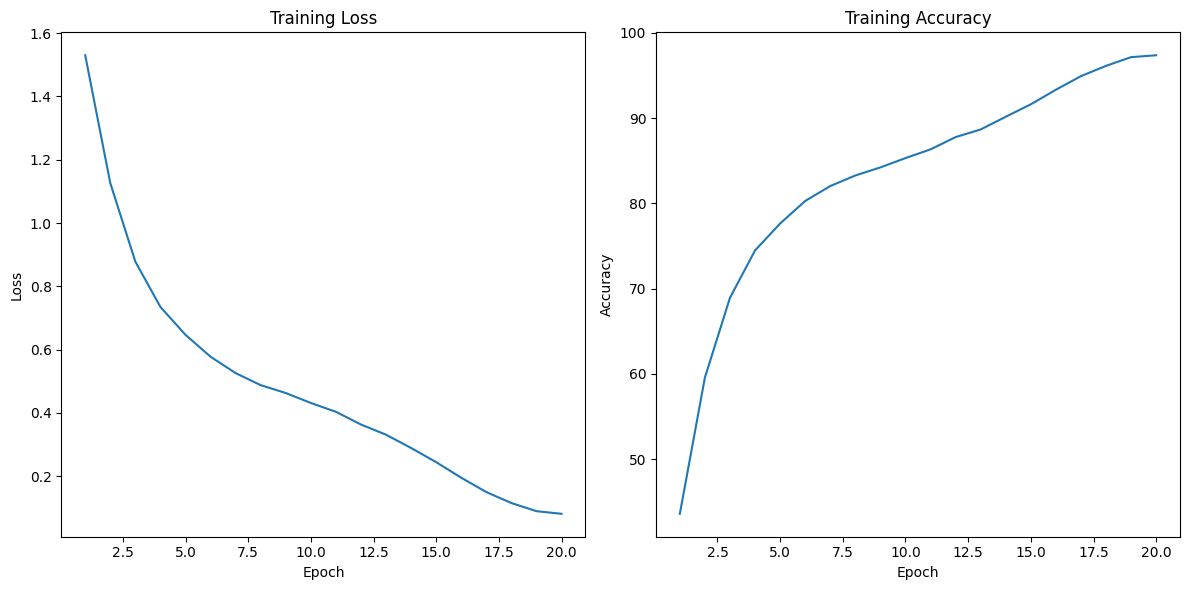

In [7]:
import matplotlib.pyplot as plt

# Plot training loss and accuracy
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].plot(range(1, EPOCHS + 1), train_losses)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Training Loss")

axes[1].plot(range(1, EPOCHS + 1), train_accuracies)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Training Accuracy")

plt.tight_layout()
plt.show()